# 16 — Final research synthesis: Hungary, USD and EUR investors

Synthesize the **recorded frozen research run**, including the full robustness history. **Run All in
the existing Miniconda base kernel**, after notebooks 02–15. This notebook reads local artifacts,
checks their provenance and calculations, and creates summary tables and figures. It performs **no
downloads, data updates, optimization or new model selection**.

The main analysis keeps **321 months, 2000-01 to 2026-09**, corrected FX pricing means, **zero equity
alphas**, and both retained covariance models, **scalar11** and **grouped21**. Historical alternatives,
free-alpha diagnostics and shorter samples remain in the audit with their own scope; they do not
replace the main specification. The snapshot's download cutoff is **2026-11-13**; the last common
usable month is September, not November.

Research application of Antell, J., & Vaihekoski, M. (2007),
[International asset pricing models and currency risk: Evidence from Finland 1970–2004](https://www.researchgate.net/publication/222411851_International_asset_pricing_models_and_currency_risk_Evidence_from_Finland_1970-2004),
*Journal of Banking & Finance*, 31(9), 2571–2590.
[DOI](https://doi.org/10.1016/j.jbankfin.2006.09.013).
This is an open-data **Hungarian adaptation**, not an exact numerical replication of Finland.

`research_synthesis_inputs.json` pins the source artifacts by SHA-256. Missing or changed inputs
stop the synthesis; they are not silently refreshed. Tables retain source notebook and case IDs.

In [1]:
LOCK_FILE="research_synthesis_inputs.json"
HAC_LAGS=[0,3,6,12]
RETAINED=["scalar11","grouped21"]
ALPHA=.05

from pathlib import Path
from io import BytesIO
import hashlib,importlib.metadata,json,os,platform,sys
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from IPython.display import display,Markdown
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
print("Python:",sys.executable);print("Packages:",versions)
lock_bytes=(ROOT/LOCK_FILE).read_bytes();lock=json.loads(lock_bytes);loaded={}
def read(path):
    path=Path(path);path=path if path.is_absolute() else ROOT/path
    relative=path.relative_to(ROOT).as_posix()
    if relative not in lock["files"]:raise ValueError(f"Unpinned synthesis input: {relative}")
    if relative not in loaded:
        raw=path.read_bytes()
        if hashlib.sha256(raw).hexdigest()!=lock["files"][relative]:raise ValueError(f"Synthesis input changed: {relative}. Review upstream results and the input lock explicitly.")
        loaded[relative]=raw
    return loaded[relative]
for path in lock["files"]:read(path)
roots={int(i):ROOT/v["root"] for i,v in lock["sources"].items()}
manifests={i:json.loads(read(roots[i]/lock["sources"][str(i)]["manifest"])) for i in roots}
def csv(stage,name,**kwargs):return pd.read_csv(BytesIO(read(roots[stage]/name)),float_precision="round_trip",**kwargs)
def parameters(stage,case):
    with np.load(BytesIO(read(roots[stage]/f"parameters_{case}.npz")),allow_pickle=False) as a:return {k:a[k].copy() for k in a.files}
source=ROOT/lock["snapshot"];sealed=json.loads(read(source/"manifest.json"))
assert sealed["sealed"] and sealed["mode"]=="fixed" and sealed["requested_end_date"]=="2026-11-13"
assert sealed["exports"]["dataset.csv"]==lock["dataset_sha256"]
for name,digest in sealed["exports"].items():assert hashlib.sha256(read(source/name)).hexdigest()==digest
for name,info in sealed["sources"].items():assert hashlib.sha256(read(source/"raw"/name)).hexdigest()==info["sha256"]
data=pd.read_csv(BytesIO(read(source/"dataset.csv")),index_col=0,float_precision="round_trip")
data.index=pd.PeriodIndex(data.index,freq="M",name="month")
assert len(data)==lock["observations"]==321 and str(data.index[0])==lock["first"]=="2000-01" and str(data.index[-1])==lock["last"]=="2026-09"
assert data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")) and data.notna().all().all()
for i,m in manifests.items():
    assert m["source_dataset_sha256"]==lock["dataset_sha256"],i
    n=m.get("observations",m.get("main_observations",m.get("state_observations")));assert n==len(data),i
    first=m.get("first",m.get("main_first",m.get("analysis_start")));last=m.get("last",m.get("main_last",m.get("analysis_end")))
    assert first==str(data.index[0]) and last==str(data.index[-1]),i
    if "HAC_lags" in m:assert m["HAC_lags"]==HAC_LAGS,i
    for name,digest in m.get("engines",{}).items():assert hashlib.sha256(read(ROOT/name)).hexdigest()==digest,(i,name)
    for name,digest in m.get("upstream_file_sha256",{}).items():assert hashlib.sha256(read(ROOT/m["upstream"]/name)).hexdigest()==digest,(i,name)
    if "conditioning_root" in m:
        for name,digest in m.get("conditioning_file_sha256",{}).items():assert hashlib.sha256(read(ROOT/m["conditioning_root"]/name)).hexdigest()==digest,(i,name)
    for name,digest in m.get("provenance_chain_sha256",{}).items():assert hashlib.sha256(read(ROOT/name)).hexdigest()==digest,(i,name)
assert manifests[13]["equity_alphas"]==manifests[15]["equity_alphas"]=="fixed zero"
assert manifests[13]["FX_means"]==manifests[15]["FX_means"]=="corrected pricing equations"
assert manifests[13]["covariance_models"]==manifests[15]["covariance_models"]==RETAINED
OUT=ROOT/"output"/"16_research_synthesis"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/"recorded_run"
OUT.mkdir(parents=True,exist_ok=True)
pd.set_option("display.max_columns",18);pd.set_option("display.max_rows",55);pd.options.display.float_format=lambda x:f"{x:.6g}"
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.15})
print(f"Verified {len(lock['files'])} pinned files; {len(data)} common frozen months; no estimation or fetching.")

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}
Verified 617 pinned files; 321 common frozen months; no estimation or fetching.


## 1. Research design and the complete evidence trail

For each investor currency, the five-vector is world, US and Hungarian **excess equity log returns**,
followed by HUF and other-currency spot log changes. Model inputs are monthly log percentage points.
Positive FX returns mean foreign-currency appreciation: HUF and EUR for a USD investor, HUF and USD
for a EUR investor. Both perspectives use the same calendar, but different cash proxies and signed
currency conditioners; this is not a pure numeraire-invariance experiment.

The corrected zero-alpha system used in the final catalog is

$$\boxed{\mu_{i,t}=\lambda_{W,t}H_{iW,t}+\lambda_{H,t}H_{iH,t}+\lambda_{O,t}H_{iO,t}
+\mathbf1_{i=US}\lambda_{US}H_{US,US,t}+\mathbf1_{i=HU}\lambda_{HU,t}H_{HU,HU,t}.}$$

It applies to **all five mean equations**, including FX. Local terms appear only in the US and
Hungarian equity rows, using their own conditional variances. In the FX-only time-variation branch,
world/local prices are constant and $\lambda_{H,t}=Z_{H,t-1}\kappa_H$,
$\lambda_{O,t}=Z_{O,t-1}\kappa_O$. A fitted varying path is not itself a constancy test.

Covariance models retain a free positive $CC'$ intercept unless targeting is explicitly stated.
`scalar11` has one shock lag and common dynamics; `grouped21` has two shock lags and one covariance
lag, sharing dynamics within World/US, Hungary and the two FX series. Targeting replaces the free
intercept with $S-\sum_j A_jSA_j'-BSB'$ and accounts for the **estimated** target in uncertainty.

The following register covers **every notebook 02–15**, all archived fit rows and every archived
restriction-test row, including unsuccessful inference and superseded models. Rows repeated across
notebooks remain source-labelled audit records; they are not independent replications. Only the
aligned 12/13 catalog enters final AIC/BIC rankings. The original tables remain available through
`source_table_index.csv` and their notebook links.

In [2]:
scope={2:"Preliminary data, instruments and return diagnostics",3:"Historical three-equity constant pricing",4:"Historical three-equity scalar/diagonal covariance",5:"Historical constant-FX prices; VAR currency means",6:"Historical world-price variation; VAR currency means",7:"Historical FX-price variation; VAR currency means",
    8:"FX mean restriction, covariance grouping, levels and post-float window",9:"Covariance alternatives and score-HAC; TV world + FX",10:"Hungarian local change/level variation; TV world + FX",11:"Zero/free equity alphas, constant/TV local; TV world + FX",12:"Corrected-mean, zero-alpha nested ladder",13:"FX-only branch and matched ladder references",14:"FX-only timing, form, regime, CPI and calendar influence",15:"FX-only innovation/return covariance targets"}
fit_files={i:("model_comparison.csv" if i==9 else "all_fit_summary.csv" if i==8 else "fit_summary.csv") for i in range(3,16)}
fit_frames={i:csv(i,name) for i,name in fit_files.items()};case_rows=[]
def case_name(stage,row):
    if "case" in row:return str(row["case"])
    parts=[row["perspective"]]
    if stage>=5:parts.append(row["covariance_model"])
    parts.append(row.get("model","with_fx" if stage==5 else "world_local"))
    return "_".join(parts)
for i,frame in fit_frames.items():
    for _,r in frame.iterrows():
        case=case_name(i,r);n=int(r.get("n",r.get("state_months",r.get("months",321))))
        ready_key=next(k for k in ["primary_regular_all_lags","regular_all_lags","ready_all_lags","sandwich_ready_all_lags","inference_ready","numerical_inference_ready"] if k in r)
        cov=r.get("covariance",r.get("covariance_model",r.get("model"))) if i>=5 else ("scalar11" if i==3 else "diagonal11")
        if i==8:cov={"scalar":"scalar11","grouped":"grouped11"}[cov]
        if i==9:cov=r["model"]
        mean=("no FX equations" if i<=4 else "VAR replacement" if i<=7 else "pricing restriction")
        if i==8:mean={"var6":"VAR replacement","paper_var1":"pricing + VAR(1) correction","paper":"pricing restriction"}[r["mean_model"]]
        alpha="free diagnostic" if i==11 and bool(r["free_alpha"]) else "zero"
        first="2008-03" if i==8 and r["variant"]=="post_float" else str(data.index[0])
        assert n==(223 if first=="2008-03" else 321),(i,case,n)
        case_rows.append({"source":i,"case":case,"perspective":r["perspective"],"covariance":cov,"scope":scope[i],"FX_means":mean,"equity_alphas":alpha,"first":first,"last":str(data.index[-1]),"state_months":n,
            "scored_months":int(r.get("scored_months",n)),"parameters":int(r.get("parameters",r.get("optimization_parameters",0))),"numerically_ready":bool(r[ready_key]),"reason":r.get("reason","see restriction/fit audit" if not r[ready_key] else "numerically ready"),"source_file":str((roots[i]/fit_files[i]).relative_to(ROOT))})
case_register=pd.DataFrame(case_rows).set_index(["source","case"])
archive_rows=[]
for i in range(3,16):
    name="local_risk_wald.csv" if i==3 else "restriction_tests.csv"
    frame=csv(i,name)
    for _,r in frame.iterrows():
        case=case_name(i,r);meta=case_register.loc[(i,case)];p=r["robust_p_value"]
        archive_rows.append({"source":i,"case":case,"perspective":meta["perspective"],"covariance":meta["covariance"],"scope":meta["scope"],"FX_means":meta["FX_means"],"equity_alphas":meta["equity_alphas"],"state_months":meta["state_months"],"scored_months":meta["scored_months"],
            "method":r.get("method","joint_QML"),"HAC_lags":int(r.get("HAC_lags",0)),"bandwidth_scope":"four fixed bandwidths" if i>=9 else "single robust covariance", "test":r.get("test",r.get("restriction")),
            "Wald_statistic":r["Wald_statistic"],"df":int(r["df"]),"robust_p_value":p,"component_holm_p":r.get("component_holm_p",np.nan),"inference_ready":bool(r.get("inference_ready",meta["numerically_ready"])) and np.isfinite(p),"reason":r.get("reason",meta["reason"]),"source_file":str((roots[i]/name).relative_to(ROOT))})
all_tests=pd.DataFrame(archive_rows)
assert not all_tests.duplicated(["source","case","method","HAC_lags","test"]).any()
def test_range(frame,pcol="robust_p_value",expected=HAC_LAGS):
    ok=frame["inference_ready"]&frame[pcol].notna();valid=frame.loc[ok];complete=set(valid["HAC_lags"])==set(expected) and len(valid)==len(expected)
    p0=valid.loc[valid["HAC_lags"].eq(0),pcol]
    low,high=valid[pcol].min(),valid[pcol].max()
    status="withheld/incomplete" if not complete else "reject at every bandwidth" if high<ALPHA else "non-reject at every bandwidth" if low>=ALPHA else "bandwidth-sensitive"
    return {"p_HAC0":p0.iloc[0] if len(p0) else np.nan,"p_min":low,"p_max":high,"complete":complete,"status":status}
hypothesis_rows=[]
for (i,case,method,test),g in all_tests.groupby(["source","case","method","test"],sort=False):
    hypothesis_rows.append({"source":i,"case":case,"method":method,"test":test,"scope":scope[i],**test_range(g,expected=HAC_LAGS if i>=9 else [0])})
hypothesis_register=pd.DataFrame(hypothesis_rows)
table_rows=[]
for relative in lock["files"]:
    path=ROOT/relative
    if path.suffix==".csv" and path.parent in roots.values():
        stage=next(i for i,p in roots.items() if path.parent==p)
        if path.name.startswith(("design_","price_paths_","premia_","Hungary_","hungary_premium_")):continue
        frame=pd.read_csv(BytesIO(read(path)))
        table_rows.append({"source":stage,"table":path.name,"rows":len(frame),"columns":len(frame.columns),"path":relative,"sha256":lock["files"][relative]})
source_table_index=pd.DataFrame(table_rows).sort_values(["source","table"])
coverage=pd.DataFrame([{"source":i,"scope":scope[i],"fit_rows":len(fit_frames[i]) if i in fit_frames else 0,"restriction_rows":int(all_tests["source"].eq(i).sum()),"indexed_tables":int(source_table_index["source"].eq(i).sum()),"notebook":next(ROOT.glob(f"{i:02d}_*.ipynb")).name} for i in range(2,16)])
display(coverage);display(case_register.groupby(level="source")["numerically_ready"].agg(["size","sum"]))
display(Markdown(f"**Archive:** {len(case_register)} source-labelled fit rows and {len(all_tests)} restriction-test records. Repeated references are retained for audit, not counted as new evidence."))

,source,scope,fit_rows,restriction_rows,indexed_tables,notebook
0,2,"Preliminary data, instruments and return diagn...",0,0,8,02_analysis.ipynb
1,3,Historical three-equity constant pricing,4,2,7,03_pricing_baseline.ipynb
2,4,Historical three-equity scalar/diagonal covari...,4,6,9,04_covariance_comparison.ipynb
3,5,Historical constant-FX prices; VAR currency means,8,8,9,05_currency_risk.ipynb
4,6,Historical world-price variation; VAR currency...,8,28,12,06_time_varying_world.ipynb
5,7,Historical FX-price variation; VAR currency means,8,56,25,07_time_varying_currency.ipynb
6,8,"FX mean restriction, covariance grouping, leve...",16,58,10,08_specification_audit.ipynb
7,9,Covariance alternatives and score-HAC; TV worl...,8,96,7,09_covariance_robustness.ipynb
8,10,Hungarian local change/level variation; TV wor...,12,272,15,10_time_varying_local.ipynb
9,11,"Zero/free equity alphas, constant/TV local; TV...",16,384,10,11_pricing_errors.ipynb


,size,sum
source,,
3,4,4
4,4,4
5,8,6
6,8,6
7,8,5
8,16,16
9,8,7
10,12,12
11,16,16


**Archive:** 160 source-labelled fit rows and 3566 restriction-test records. Repeated references are retained for audit, not counted as new evidence.

## 2. Final model comparison: disagreement between criteria remains

Use the 20 jointly estimated models from notebooks 12/13: five pricing structures × two covariance
models × two perspectives. Every row has the same five series, common sample, corrected FX means
and zero alphas. Recalculate AIC/BIC and their differences **within each perspective**. The FX-only
branch has constant world/local prices and time-varying FX prices; constant-price models still
include currency risk prices.

Do not put shorter samples, zero-weight likelihood objectives, free-alpha diagnostic fits, earlier
VAR specifications or two-step covariance-targeted estimators into this ranking. In particular, the
reduced second-stage target parameter count is not an ordinary AIC/BIC penalty for the whole estimator.
The catalog is the tested set, not an exhaustive search of possible pricing structures.

In [3]:
catalog=csv(13,"expanded_model_catalog.csv").set_index("case")
assert len(catalog)==20 and catalog["n"].eq(len(data)).all() and set(catalog["covariance"])==set(RETAINED)
for criterion,penalty in [("AIC",2.),("BIC",np.log(len(data)))]:
    np.testing.assert_allclose(catalog[criterion],-2*catalog["loglik"]+penalty*catalog["parameters"],atol=2e-9,rtol=1e-12)
    delta=catalog[criterion]-catalog.groupby("perspective")[criterion].transform("min")
    np.testing.assert_allclose(delta,catalog[f"{criterion}_from_best"],atol=2e-9,rtol=1e-12)
winner_rows=[]
for currency in ["USD","EUR"]:
    q=catalog[catalog["perspective"].eq(currency)]
    for criterion in ["AIC","BIC"]:
        case=q[criterion].idxmin();r=q.loc[case]
        winner_rows.append({"perspective":currency,"criterion":criterion,"case":case,"pricing_model":r["model"],"covariance":r["covariance"],"criterion_value":r[criterion],"variance_flags":r["variance_flags"],"cross_flags":r["cross_flags"]})
winners=pd.DataFrame(winner_rows)
main_hypotheses=hypothesis_register[(hypothesis_register["source"].eq(13)&hypothesis_register["case"].str.endswith("_FX"))].copy()
main_hypotheses=main_hypotheses.merge(case_register.reset_index()[["source","case","perspective","covariance"]],on=["source","case"],validate="many_to_one")
display(winners);display(catalog[["perspective","covariance","model","parameters","AIC_from_best","BIC_from_best","variance_flags","cross_flags"]])
display(main_hypotheses[["perspective","covariance","test","p_HAC0","p_min","p_max","status"]])
display(Markdown("**Recorded result:** AIC favors grouped21 with FX-only time variation in both perspectives; scalar11 FX-only is within about 1.6 AIC points. BIC favors scalar11 with all prices constant. Thus the FX-only model is a useful parsimonious research branch, not an unambiguous winner under every criterion."))

,perspective,criterion,case,pricing_model,covariance,criterion_value,variance_flags,cross_flags
0,USD,AIC,USD_grouped21_FX,TV FX only,grouped21,7499.27,1,0
1,USD,BIC,USD_scalar11_S1,Constant prices,scalar11,7596.59,4,3
2,EUR,AIC,EUR_grouped21_FX,TV FX only,grouped21,7493.61,0,0
3,EUR,BIC,EUR_scalar11_S1,Constant prices,scalar11,7597.59,3,0


,perspective,covariance,model,parameters,AIC_from_best,BIC_from_best,variance_flags,cross_flags
case,,,,,,,,
USD_scalar11_S1,USD,scalar11,Constant prices,22,14.3577,0,4,3
USD_scalar11_S2,USD,scalar11,TV world,25,18.3445,15.3012,4,1
USD_scalar11_S3,USD,scalar11,TV world + FX,34,7.36023,38.2598,4,0
USD_scalar11_S4,USD,scalar11,TV world + FX + HU local,36,11.0196,49.4621,4,0
USD_grouped21_S1,USD,grouped21,Constant prices,29,14.4483,26.4908,2,2
USD_grouped21_S2,USD,grouped21,TV world,32,18.0933,41.45,2,1
USD_grouped21_S3,USD,grouped21,TV world + FX,41,5.44103,62.7407,1,0
USD_grouped21_S4,USD,grouped21,TV world + FX + HU local,43,9.33399,74.1766,1,0
EUR_scalar11_S1,EUR,scalar11,Constant prices,22,21.0092,0,3,0


,perspective,covariance,test,p_HAC0,p_min,p_max,status
0,USD,scalar11,World price zero,0.0105179,0.0105179,0.0611894,bandwidth-sensitive
1,USD,scalar11,FX prices zero,0.00078527,2.0012e-09,0.00078527,reject at every bandwidth
2,USD,scalar11,Hungarian local price zero,0.0860609,0.0860609,0.149644,non-reject at every bandwidth
3,USD,scalar11,Local prices jointly zero,0.0646712,0.0383649,0.0646712,bandwidth-sensitive
4,USD,scalar11,FX prices constant,0.000316678,2.15812e-09,0.000316678,reject at every bandwidth
5,USD,grouped21,World price zero,0.00475988,0.00475988,0.0416217,reject at every bandwidth
6,USD,grouped21,FX prices zero,0.00065075,4.7368e-10,0.00065075,reject at every bandwidth
7,USD,grouped21,Hungarian local price zero,0.0854183,0.0854183,0.130474,non-reject at every bandwidth
8,USD,grouped21,Local prices jointly zero,0.0604305,0.038996,0.0604305,bandwidth-sensitive
9,USD,grouped21,FX prices constant,0.000280131,8.03808e-09,0.000280131,reject at every bandwidth


**Recorded result:** AIC favors grouped21 with FX-only time variation in both perspectives; scalar11 FX-only is within about 1.6 AIC points. BIC favors scalar11 with all prices constant. Thus the FX-only model is a useful parsimonious research branch, not an unambiguous winner under every criterion.

## 3. FX-only robustness, with the shared baseline counted once

Combine notebook 14's 36 baseline/sensitivity cases with only the **eight new targeted cases** from
15. Verify that 13's FX baseline, 14's baseline and 15's free reference agree before consolidating.
This gives **44 reported cases**, not 48, and does not make them independent studies.

Retain every check: inflation lag 3, HUF gap level, removal of the regime predictor, removal of direct
US-CPI predictors, zero likelihood terms at carried-CPI dates, zero likelihood terms in 2008–09,
2020 and 2022–23, the innovation second-moment target, and the centered-return covariance benchmark.
Every case retains all 321 GARCH updates. Zero-weight checks assess likelihood influence; crisis
returns and flagged innovations still affect later states. They are not crisis-free or missing-data-free
samples. The whole-sample no-US-CPI check removes direct conditioners involving US inflation.

Reconstruct all five pricing means from the saved parameters/designs/covariances, verify zero alphas,
and recalculate the primary Wald tests from saved covariance matrices. Targeting uses **target-adjusted**
uncertainty; target-fixed tests remain in the full archive as comparisons only. A boundary fit stays
visible with inference withheld. For individual FX blocks, use the archived two-block Holm adjustment;
this adjustment does not cover specification search. Constancy and zero pricing are separate nulls.

In [4]:
def design(stage,case):
    d={a:csv(stage,f"design_{case}_{a}.csv",index_col=0) for a in ["W","H","O","L"]}
    for z in d.values():assert pd.PeriodIndex(z.index,freq="M").equals(data.index)
    return {a:z.to_numpy() for a,z in d.items()}
def positions(d):
    w=5+d["W"].shape[1]-1;h=w+d["H"].shape[1]-1;o=h+d["O"].shape[1]-1
    return {"W":np.r_[0,np.arange(5,w)],"H":np.r_[3,np.arange(w,h)],"O":np.r_[4,np.arange(h,o)],"L":np.r_[2,np.arange(o,o+d["L"].shape[1]-1)]}
def verify_means(a,d,currency):
    assert np.array_equal(a["equity_alphas"],np.zeros(3)) and a["H"].shape==(len(data),5,5)
    ix=positions(d);prices={label:.01*(d[label]@a["theta"][j]) for label,j in ix.items()}
    expected=np.einsum("tij,tj->ti",a["H"][:,:,[0,3,4]],np.c_[prices["W"],prices["H"],prices["O"]])
    expected[:,1]+=.01*a["theta"][1]*a["H"][:,1,1];expected[:,2]+=prices["L"]*a["H"][:,2,2]
    np.testing.assert_allclose(expected,a["mu"],atol=1e-10,rtol=1e-11)
    y=np.c_[data[[f"rx_{e}_{currency.lower()}" for e in ["world","us","hu"]]]*100,data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    residual=y-expected;np.testing.assert_allclose(residual,a["residuals"],atol=1e-10,rtol=1e-11)
    sign,logdet=np.linalg.slogdet(a["H"]);assert (sign>0).all() and np.linalg.eigvalsh(a["H"]).min()>0
    loss=.5*(5*np.log(2*np.pi)+logdet+np.einsum("ti,ti->t",residual,np.linalg.solve(a["H"],residual[...,None])[...,0]))
    return prices,-loss.sum(),float(np.max(np.abs(expected-a["mu"])))
verification_rows=[]
for case,r in catalog.iterrows():
    stage=13 if case.endswith("_FX") else 12;a=parameters(stage,case);d=design(stage,case)
    prices,ll,error=verify_means(a,d,r["perspective"])
    assert len(a["theta"])==r["parameters"]
    np.testing.assert_allclose(ll,r["loglik"],atol=2e-8,rtol=0)
    verification_rows.append({"source":stage,"case":case,"role":"final catalog","max_mean_error":error,"zero_alphas":True})
stress=csv(14,"summary.csv");targets=csv(15,"summary.csv")
selected=pd.concat([stress.assign(source=14,check=stress["variant"],method="joint_QML"),targets[targets["target"].ne("free")].assign(source=15,check=lambda f:"target_"+f["target"])],ignore_index=True)
assert not selected.duplicated(["perspective","covariance","check"]).any()
for currency in ["USD","EUR"]:
    for cov in RETAINED:
        b=parameters(13,f"{currency}_{cov}_FX");s=parameters(14,f"{currency}_{cov}_baseline");t=parameters(15,f"{currency}_{cov}_free")
        for field in ["theta","H","mu","residuals"]:
            np.testing.assert_allclose(b[field],s[field],atol=1e-9,rtol=1e-10);np.testing.assert_allclose(b[field],t[field],atol=1e-9,rtol=1e-10)
        for h in HAC_LAGS:
            np.testing.assert_allclose(b[f"covariance_HAC{h}"],s[f"covariance_HAC{h}"],atol=2e-6,rtol=2e-6)
            np.testing.assert_allclose(b[f"covariance_HAC{h}"],t[f"covariance_joint_QML_HAC{h}"],atol=2e-6,rtol=2e-6)
def wald(theta,V,j):
    v=V[np.ix_(j,j)];valid=np.isfinite(v).all() and np.linalg.eigvalsh(v).min()>0 and np.linalg.cond(v)<1e9
    statistic=theta[j]@np.linalg.solve(v,theta[j]) if valid else np.nan
    return statistic,chi2.sf(statistic,len(j)) if valid else np.nan
robust_rows=[]
for _,r in selected.iterrows():
    stage,case=int(r["source"]),r["case"];a=parameters(stage,case);d=design(stage,case);ix=positions(d)
    assert d["W"].shape[1]==d["L"].shape[1]==1
    prices,ll,error=verify_means(a,d,r["perspective"])
    q=all_tests[(all_tests["source"].eq(stage))&all_tests["case"].eq(case)&all_tests["method"].eq(r["method"])].copy()
    restrictions={"FX prices constant":np.r_[ix["H"][1:],ix["O"][1:]],"FX prices zero":np.r_[ix["H"],ix["O"]],"HUF price constant":ix["H"][1:],"Other FX price constant":ix["O"][1:],
        "HUF price zero":ix["H"],"Other FX price zero":ix["O"],"World price zero":ix["W"],"Hungarian local price zero":ix["L"],"Local prices jointly zero":np.r_[1,ix["L"]]}
    for h in HAC_LAGS:
        V=a[f"covariance_HAC{h}" if stage==14 else f"covariance_target_adjusted_HAC{h}"]
        for label,j in restrictions.items():
            row=q[q["HAC_lags"].eq(h)&q["test"].eq(label)].iloc[0];stat,p=wald(a["theta"],V,j)
            assert row["df"]==len(j)
            np.testing.assert_allclose([stat,p],[row["Wald_statistic"],row["robust_p_value"]],atol=2e-8,rtol=2e-9,equal_nan=True)
        for pair in [("HUF price constant","Other FX price constant"),("HUF price zero","Other FX price zero")]:
            rows=[q[q["HAC_lags"].eq(h)&q["test"].eq(label)].iloc[0] for label in pair];pp=np.array([row["robust_p_value"] for row in rows])
            if np.isfinite(pp).all():
                order=np.argsort(pp);adjusted=np.empty(2);adjusted[order]=np.minimum(1,np.maximum.accumulate(pp[order]*np.array([2,1])))
            else:adjusted=np.full(2,np.nan)
            np.testing.assert_allclose(adjusted,[row["component_holm_p"] for row in rows],atol=1e-12,rtol=1e-12,equal_nan=True)
    joint=test_range(q[q["test"].eq("FX prices constant")]);zero=test_range(q[q["test"].eq("FX prices zero")])
    hu=test_range(q[q["test"].eq("HUF price constant")],"component_holm_p");other=test_range(q[q["test"].eq("Other FX price constant")],"component_holm_p")
    n_scored=int(a["weights"].sum()) if "weights" in a else len(data)
    if stage==14:assert n_scored==r["scored_months"]
    reasons="; ".join(sorted(set(q.loc[~q["inference_ready"],"reason"]))) or "numerically ready"
    robust_rows.append({"source":stage,"case":case,"perspective":r["perspective"],"covariance":r["covariance"],"check":r["check"],"method":r["method"],"state_months":len(data),"scored_months":n_scored,
        "regular":bool(r["regular_all_lags"]),"reason":reasons,**{f"{prefix}_{key}":value for prefix,curve in [("joint",joint),("zero",zero),("HUF",hu),("other",other)] for key,value in curve.items()},
        "variance_flags":int(r.get("variance_flags_full_path",np.nan) if stage==14 else r["variance_flags"]),"cross_flags":int(r.get("cross_flags_full_path",np.nan) if stage==14 else r["cross_flags"])})
    verification_rows.append({"source":stage,"case":case,"role":"FX-only robustness","max_mean_error":error,"zero_alphas":True})
fx_robustness=pd.DataFrame(robust_rows).set_index(["perspective","covariance","check"])
verification=pd.DataFrame(verification_rows)
robust_counts=fx_robustness.reset_index().groupby(["perspective","covariance"]).agg(cases=("case","size"),regular=("regular","sum"),complete_joint=("joint_complete","sum"),largest_joint_p=("joint_p_max","max"))
robust_counts["reject_every_bandwidth"]=fx_robustness.reset_index().assign(reject=lambda f:f["regular"]&f["joint_complete"]&f["joint_p_max"].lt(ALPHA)).groupby(["perspective","covariance"])["reject"].sum()
display(robust_counts);display(fx_robustness[["scored_months","joint_p_HAC0","joint_p_max","HUF_p_HAC0","HUF_p_max","other_p_max","regular"]])
display(fx_robustness.loc[~fx_robustness["regular"],["case","scored_months","reason"]])

cases  regular  complete_joint  largest_joint_p  \
perspective covariance                                                    
EUR         grouped21      11       10              10       0.00426564   
            scalar11       11       11              11        0.0037587   
USD         grouped21      11       11              11       0.00830937   
            scalar11       11       11              11         0.010149   

                        reject_every_bandwidth  
perspective covariance                          
EUR         grouped21                       10  
            scalar11                        11  
USD         grouped21                       11  
            scalar11                        11

scored_months  joint_p_HAC0  \
perspective covariance check                                             
USD         scalar11   baseline                      321   0.000316678   
                       lag3                          321   0.000531366   
                       gap_level                     321    0.00048525   
                       no_regime                     321   0.000414501   
                       no_US_CPI                     321      0.010149   
                       CPI_terms0                    319    0.00028345   
                       block_2008_09                 297     7.882e-07   
                       block_2020                    309   0.000594561   
                       block_2022_23                 297   0.000158435   
            grouped21  baseline                      321   0.000280131   
                       lag3                          321   0.000304789   
                       gap_level                     321   0.000325938   
                       no_regime                     321   0.000656584   
                       no_US_CPI                     321    0.00830937   
                       CPI_terms0                    319   0.000239812   
                       block_2008_09                 297   0.000249909   
                       block_2020                    309   0.000814853   
                       block_2022_23                 297   0.000448594   
EUR         scalar11   baseline                      321   7.69171e-06   
                       lag3                          321     0.0037587   
                       gap_level                     321    0.00154243   
                       no_regime                     321    4.6579e-06   
                       no_US_CPI                     321   0.000313868   
                       CPI_terms0                    320   6.85063e-06   
                       block_2008_09                 297   1.61539e-07   
                       block_2020                    309   1.49378e-05   
                       block_2022_23                 297   7.29652e-06   
            grouped21  baseline                      321   2.74192e-05   
                       lag3                          321    0.00426564   
                       gap_level                     321     0.0021974   
                       no_regime                     321   1.13278e-05   
                       no_US_CPI                     321   0.000570743   
                       CPI_terms0                    320   2.41245e-05   
                       block_2008_09                 297   5.03408e-06   
                       block_2020                    309   7.26039e-05   
                       block_2022_23                 297           NaN   
USD         scalar11   target_innovations            321   9.19704e-05   
                       target_returns                321   2.05962e-06   
            grouped21  target_innovations            321   0.000158596   
                       target_returns                321   2.77963e-06   
EUR         scalar11   target_innovations            321   3.54052e-06   
                       target_returns                321   2.51699e-08   
            grouped21  target_innovations            321   1.71245e-05   
                       target_returns                321   8.63767e-08   

                                           joint_p_max  HUF_p_HAC0  \
perspective covariance check                                         
USD         scalar11   baseline            0.000316678   0.0781585   
                       lag3                0.000531366    0.112991   
                       gap_level            0.00048525    0.219632   
                       no_regime           0.000414501    0.127941   
                       no_US_CPI              0.010149    0.287691   
                       CPI_terms0           0.00028345   0.0741275   
                       block_2008_09         7.882e-07   0.0761265   
        

,,,case,scored_months,reason
perspective,covariance,check,,,
EUR,grouped21,block_2022_23,EUR_grouped21_block_2022_23,297,parameter bound


## 4. Qualifications from the full robustness history

**The currency-mean restriction matters.** Notebook 08's VAR(6) replacement does not reject FX-price
constancy at 5% in its four full-sample scalar/grouped cases. Corrected pricing means and the nested
VAR(1) correction give different evidence. The final conclusion is conditional on the pricing mean
system; do not describe it as robust to every FX forecasting specification.

**Separate HUF evidence is weaker than the joint result.** In the USD FX-only baseline, neither
Holm-adjusted currency-block constancy test rejects at HAC(0). For EUR, baseline HUF variation is
supported, but the lag-3 and gap-level checks cease rejecting HUF constancy across all bandwidths.
The other FX block can retain evidence even when HUF does not. Never infer both individual currency
prices vary solely from a joint rejection.

**World/local variation and alphas have a model scope.** The world-constancy test in S3 is the direct
nested check leading to the FX-only branch. Hungarian local variation and free-equity-alpha checks
were run with **time-varying world and FX prices**. They do not directly test an FX-only-plus-local
extension or an FX-only free-alpha model. Preserve zero alphas in the current main model, and describe
their earlier non-rejection as a diagnostic on those tested branches, not proof of correct FX-only pricing.
Hungarian alpha intervals in those diagnostics are wide. The five-structure catalog does not include
every combination of world/local variation.

**Numerical and economic adequacy differ.** The retired VAR diagonal fits, the USD corrected-mean
diagonal covariance fit and the EUR grouped 2022–23 zero-weight fit stay in the record. Their withheld
inference is not a valid rejection or non-rejection. Residual diagnostics are approximate screens
after GARCH estimation; HAC adjusts uncertainty and does not repair misspecification.

In [5]:
mean_audit=all_tests[(all_tests["source"].eq(8))&all_tests["test"].isin(["FX prices constant","Paper FX mean restriction"])].merge(fit_frames[8][["case","mean_model","variant"]],on="case",validate="many_to_one")
local_alpha=hypothesis_register[((hypothesis_register["source"].eq(10))&hypothesis_register["test"].eq("Hungarian local price constant"))|((hypothesis_register["source"].eq(11))&hypothesis_register["test"].eq("Equity alphas jointly zero"))|((hypothesis_register["source"].eq(12))&hypothesis_register["case"].str.endswith("_S3")&hypothesis_register["test"].eq("World price constant"))].copy()
alpha_intervals=csv(11,"alpha_estimates.csv");alpha_intervals=alpha_intervals[alpha_intervals["HAC_lags"].eq(0)&alpha_intervals["equity"].eq("Hungary")].copy()
base_diagnostics=fit_frames[13].loc[fit_frames[13]["tag"].eq("FX"),["case","perspective","covariance","mean_flags","variance_flags","variance_flags_holm","cross_flags"]].copy()
retired=csv(8,"retired_diagonal_audit.csv")
withheld=case_register.loc[~case_register["numerically_ready"]].copy()
critical_checks=fx_robustness.reset_index().query("check in ['baseline','lag3','gap_level','no_US_CPI','target_innovations']")
display(Markdown("**Currency-mean, instrument-level and shorter-window audit (08)**"))
display(mean_audit[["case","mean_model","variant","state_months","test","robust_p_value","inference_ready"]])
display(Markdown("**World/local variation and alpha diagnostics, with their original branch scope**"))
display(local_alpha[["source","case","test","p_HAC0","p_min","p_max","status"]]);display(alpha_intervals[["case","alpha_monthly_pp","lower95_pp","upper95_pp"]])
display(Markdown("**Main FX-only residual flags — nominal and within-family Holm adjustment**"));display(base_diagnostics)
display(Markdown("**All numerically ineligible archived fit rows; repeated references remain source-labelled**"));display(withheld);display(retired)
display(Markdown("**HUF and other-currency block sensitivity — Holm-adjusted within each two-block family**"))
display(critical_checks[["perspective","covariance","check","HUF_p_HAC0","HUF_p_min","HUF_p_max","other_p_max"]])

**Currency-mean, instrument-level and shorter-window audit (08)**

,case,mean_model,variant,state_months,test,robust_p_value,inference_ready
0,USD_var6_scalar_full,var6,full,321,FX prices constant,0.330591,True
1,USD_var6_grouped_full,var6,full,321,FX prices constant,0.359474,True
2,USD_paper_scalar_full,paper,full,321,FX prices constant,0.000564707,True
3,USD_paper_grouped_full,paper,full,321,FX prices constant,0.00207136,True
4,USD_paper_var1_scalar_full,paper_var1,full,321,Paper FX mean restriction,0.340337,True
5,USD_paper_var1_scalar_full,paper_var1,full,321,FX prices constant,0.00181301,True
6,USD_paper_var1_grouped_full,paper_var1,full,321,Paper FX mean restriction,0.363159,True
7,USD_paper_var1_grouped_full,paper_var1,full,321,FX prices constant,0.00300763,True
8,EUR_var6_scalar_full,var6,full,321,FX prices constant,0.0917426,True
9,EUR_var6_grouped_full,var6,full,321,FX prices constant,0.199538,True


**World/local variation and alpha diagnostics, with their original branch scope**

,source,case,test,p_HAC0,p_min,p_max,status
192,10,USD_scalar11_change,Hungarian local price constant,0.828827,0.825791,0.845533,non-reject at every bandwidth
198,10,USD_scalar11_level,Hungarian local price constant,0.612117,0.512074,0.672716,non-reject at every bandwidth
209,10,USD_grouped21_change,Hungarian local price constant,0.949303,0.943071,0.949303,non-reject at every bandwidth
215,10,USD_grouped21_level,Hungarian local price constant,0.593889,0.498634,0.66719,non-reject at every bandwidth
226,10,EUR_scalar11_change,Hungarian local price constant,0.853224,0.853224,0.887612,non-reject at every bandwidth
232,10,EUR_scalar11_level,Hungarian local price constant,0.692824,0.614418,0.745761,non-reject at every bandwidth
243,10,EUR_grouped21_change,Hungarian local price constant,0.835465,0.835465,0.876115,non-reject at every bandwidth
249,10,EUR_grouped21_level,Hungarian local price constant,0.695714,0.625476,0.742425,non-reject at every bandwidth
260,11,USD_scalar11_constant_free,Equity alphas jointly zero,0.541112,0.541112,0.697818,non-reject at every bandwidth
273,11,USD_scalar11_change_free,Equity alphas jointly zero,0.523664,0.523664,0.673615,non-reject at every bandwidth


,case,alpha_monthly_pp,lower95_pp,upper95_pp
0,EUR_grouped21_change_free,1.58722,-1.15736,4.33179
12,EUR_grouped21_constant_free,1.61477,-1.05668,4.28623
24,EUR_scalar11_change_free,1.26521,-1.0153,3.54573
36,EUR_scalar11_constant_free,1.30037,-0.932825,3.53357
48,USD_grouped21_change_free,1.35482,-1.08104,3.79068
60,USD_grouped21_constant_free,1.34958,-0.997657,3.69682
72,USD_scalar11_change_free,1.56012,-0.49303,3.61326
84,USD_scalar11_constant_free,1.51674,-0.516411,3.54989


**Main FX-only residual flags — nominal and within-family Holm adjustment**

... (2 outputs left out)

perspective  covariance  \
source case                                                   
5      EUR_diagonal_no_fx                   EUR    diagonal   
       EUR_diagonal_with_fx                 EUR    diagonal   
6      EUR_diagonal_constant                EUR    diagonal   
       EUR_diagonal_time_varying            EUR    diagonal   
7      EUR_diagonal_constant_fx             EUR    diagonal   
       EUR_diagonal_time_varying_fx         EUR    diagonal   
       USD_diagonal_time_varying_fx         USD    diagonal   
9      USD_diagonal11                       USD  diagonal11   
14     EUR_grouped21_block_2022_23          EUR   grouped21   

                                                                                 scope  \
source case                                                                              
5      EUR_diagonal_no_fx            Historical constant-FX prices; VAR currency means   
       EUR_diagonal_with_fx          Historical constant-FX prices; VAR currency means   
6      EUR_diagonal_constant         Historical world-price variation; VAR currency...   
       EUR_diagonal_time_varying     Historical world-price variation; VAR currency...   
7      EUR_diagonal_constant_fx      Historical FX-price variation; VAR currency means   
       EUR_diagonal_time_varying_fx  Historical FX-price variation; VAR currency means   
       USD_diagonal_time_varying_fx  Historical FX-price variation; VAR currency means   
9      USD_diagonal11                Covariance alternatives and score-HAC; TV worl...   
14     EUR_grouped21_block_2022_23   FX-only timing, form, regime, CPI and calendar...   

                                                FX_means equity_alphas  \
source case                                                              
5      EUR_diagonal_no_fx                VAR replacement          zero   
       EUR_diagonal_with_fx              VAR replacement          zero   
6      EUR_diagonal_constant             VAR replacement          zero   
       EUR_diagonal_time_varying         VAR replacement          zero   
7      EUR_diagonal_constant_fx          VAR replacement          zero   
       EUR_diagonal_time_varying_fx      VAR replacement          zero   
       USD_diagonal_time_varying_fx      VAR replacement          zero   
9      USD_diagonal11                pricing restriction          zero   
14     EUR_grouped21_block_2022_23   pricing restriction          zero   

                                       first     last  state_months  \
source case                                                           
5      EUR_diagonal_no_fx            2000-01  2026-09           321   
       EUR_diagonal_with_fx          2000-01  2026-09           321   
6      EUR_diagonal_constant         2000-01  2026-09           321   
       EUR_diagonal_time_varying     2000-01  2026-09           321   
7      EUR_diagonal_constant_fx      2000-01  2026-09           321   
       EUR_diagonal_time_varying_fx  2000-01  2026-09           321   
       USD_diagonal_time_varying_fx  2000-01  2026-09           321   
9      USD_diagonal11                2000-01  2026-09           321   
14     EUR_grouped21_block_2022_23   2000-01  2026-09           321   

                                     scored_months  parameters  \
source case                                                      
5      EUR_diagonal_no_fx                      321          54   
       EUR_diagonal_with_fx                    321          56   
6      EUR_diagonal_constant                   321          56   
       EUR_diagonal_time_varying               321          59   
7      EUR_diagonal_constant_fx                321          59   
       EUR_diagonal_time_varying_fx            321          68   
       USD_diagonal_time_varying_fx            321          68   
9      USD_diagonal11                          321          42   
14     EUR_grouped21_block_2022_23             297          38   

                           

,perspective,status,closest_parameter_position,bound_parameter,value,distance_to_bound,Hessian_condition,inference_ready
0,USD,retained for audit; no new diagonal fits,57,"normalised intercept Cholesky C[5,5] log diagonal",-8,0,1.92738e+09,False
1,EUR,retained for audit; no new diagonal fits,57,"normalised intercept Cholesky C[5,5] log diagonal",-8,0,7.48028e+12,False


**HUF and other-currency block sensitivity — Holm-adjusted within each two-block family**

,perspective,covariance,check,HUF_p_HAC0,HUF_p_min,HUF_p_max,other_p_max
0,USD,scalar11,baseline,0.0781585,0.009513,0.0781585,0.0596175
1,USD,scalar11,lag3,0.112991,0.0151911,0.112991,0.111646
2,USD,scalar11,gap_level,0.219632,0.0352649,0.219632,0.219632
4,USD,scalar11,no_US_CPI,0.287691,0.211656,0.287691,0.287691
9,USD,grouped21,baseline,0.0673183,0.0164076,0.0673183,0.0673183
10,USD,grouped21,lag3,0.0999417,0.0111805,0.0999417,0.0999417
11,USD,grouped21,gap_level,0.180094,0.072241,0.180094,0.180094
13,USD,grouped21,no_US_CPI,0.158434,0.1535,0.195358,0.355473
18,EUR,scalar11,baseline,0.00765807,0.00029511,0.00765807,0.00765807
19,EUR,scalar11,lag3,0.491728,0.377427,0.491728,0.00737957


## 5. Economic interpretation and the public-data adaptations

The decomposition below uses **the four FX-only free-intercept baseline fits**, not whichever
sensitivity produces the smallest p-value. Components sum to the fitted Hungarian conditional
excess-return mean. Report monthly log percentage points; do not label them realized returns,
out-of-sample forecasts, causal effects or portfolio profits. Components can cancel, so percentage
shares of the fitted total are not reported. The sample-average innovation is not a fitted alpha.

Main data adaptations remain visible: BUX total returns; French developed-market and US market
proxies rather than the paper's original indices; ECB FX; French USD cash and a one-month Euribor
EUR cash proxy; FRED global conditioners/US CPI and Eurostat HICP. No ETF was substituted into the
recorded dataset. Dividend yield is omitted as a conditioner. A floating-regime dummy adapts the
Finnish policy indicator; it does not identify ownership liberalization or a causal policy effect.

Global market conditioners use lag 1. Inflation conditioners use lag 2 in the baseline; HUF uses
the gap change and the other FX price the US/EA gap level. The latter remains persistent. The
one-month US annual-inflation-rate carry is flagged; no return or CPI index was interpolated.
Publication-lag conventions and whole-sample normalization do not turn revised historical data
into real-time vintages or an out-of-sample exercise.

In [6]:
premium_rows,reconciliation_rows=[],[]
for currency in ["USD","EUR"]:
    for cov in RETAINED:
        case=f"{currency}_{cov}_FX";p=csv(13,f"Hungary_decomposition_{case}.csv",index_col=0)
        assert pd.PeriodIndex(p.index,freq="M").equals(data.index) and p.notna().all().all()
        np.testing.assert_allclose(p[["world","HUF_FX","other_FX","local"]].sum(axis=1),p["total"],atol=1e-11,rtol=1e-11)
        a=parameters(13,case);np.testing.assert_allclose(p["total"],a["mu"][:,2],atol=1e-11,rtol=1e-11)
        for component in ["world","HUF_FX","other_FX","local","total"]:
            premium_rows.append({"perspective":currency,"covariance":cov,"component":component,"mean_monthly_log_pp":p[component].mean(),"sd_monthly_log_pp":p[component].std(ddof=1)})
        observed=data[f"rx_hu_{currency.lower()}"].mean()*100;residual=a["residuals"][:,2].mean()
        np.testing.assert_allclose(observed,p["total"].mean()+residual,atol=1e-11,rtol=1e-11)
        reconciliation_rows.append({"case":case,"observed_excess_mean_log_pp":observed,"fitted_mean_log_pp":p["total"].mean(),"mean_innovation_log_pp":residual,"equity_alpha_fixed":0.})
premium_summary=pd.DataFrame(premium_rows).set_index(["perspective","covariance","component"]).sort_index()
mean_reconciliation=pd.DataFrame(reconciliation_rows).set_index("case")
source_map=pd.DataFrame([
    ("Hungarian equity","BUX total-return index in HUF","BSE",next(v["url"] for k,v in sealed["sources"].items() if k.startswith("bux_"))),
    ("World equity","Developed-market return proxy","Ken French",sealed["sources"]["world_factors.zip"]["url"]),
    ("US equity / USD cash","US market and cash series","Ken French",sealed["sources"]["us_factors.zip"]["url"]),
    ("EUR cash","One-month Euribor proxy","ECB",sealed["sources"]["ecb_euribor_1m.csv"]["url"]),
    ("FX","HUF/EUR and USD/EUR reference rates","ECB",sealed["sources"]["ecb_fx.csv"]["url"]),
    ("Global instruments / US inflation","GS10, TB3MS, BAA, AAA, CPIAUCNS","FRED public CSV",sealed["sources"]["fred.csv"]["url"]),
    ("Hungarian / EA inflation","HICP total indices","Eurostat",sealed["sources"]["eurostat_hicp.json"]["url"])],columns=["role","recorded_proxy","provider","frozen_source_url"])
constant_prices=csv(13,"constant_price_summary.csv").drop(columns="Unnamed: 0",errors="ignore")
display(source_map);display(premium_summary);display(mean_reconciliation)
display(Markdown("**Constant world/local risk-price estimates and HAC(0) pointwise intervals**"))
display(constant_prices.loc[constant_prices["HAC_lags"].eq(0),["case","price","estimate","lower95","upper95"]])

,role,recorded_proxy,provider,frozen_source_url
0,Hungarian equity,BUX total-return index in HUF,BSE,https://www.bse.hu/Prices-and-Markets/Data-dow...
1,World equity,Developed-market return proxy,Ken French,https://mba.tuck.dartmouth.edu/pages/faculty/k...
2,US equity / USD cash,US market and cash series,Ken French,https://mba.tuck.dartmouth.edu/pages/faculty/k...
3,EUR cash,One-month Euribor proxy,ECB,https://data-api.ecb.europa.eu/service/data/FM...
4,FX,HUF/EUR and USD/EUR reference rates,ECB,https://data-api.ecb.europa.eu/service/data/EX...
5,Global instruments / US inflation,"GS10, TB3MS, BAA, AAA, CPIAUCNS",FRED public CSV,https://fred.stlouisfed.org/graph/fredgraph.cs...
6,Hungarian / EA inflation,HICP total indices,Eurostat,https://ec.europa.eu/eurostat/api/disseminatio...


mean_monthly_log_pp  sd_monthly_log_pp
perspective covariance component                                        
EUR         grouped21  HUF_FX               -0.371953            1.22058
                       local                 0.509274          0.0870815
                       other_FX              0.158179           0.456243
                       total                 0.967443            1.41828
                       world                 0.671944           0.226609
            scalar11   HUF_FX               -0.425939            1.26762
                       local                 0.505257           0.118245
                       other_FX              0.175869           0.577923
                       total                 0.928939            1.45349
                       world                 0.673751           0.239988
USD         grouped21  HUF_FX               -0.934299              2.125
                       local                 0.481346          0.0924702
                       other_FX              0.395384            1.26622
                       total                  1.02931            1.77182
                       world                  1.08688           0.371858
            scalar11   HUF_FX                -0.99625             2.2448
                       local                 0.445318           0.115853
                       other_FX              0.398075            1.52914
                       total                 0.883971            1.76859
                       world                  1.03683           0.373073

,observed_excess_mean_log_pp,fitted_mean_log_pp,mean_innovation_log_pp,equity_alpha_fixed
case,,,,
USD_scalar11_FX,0.639019,0.883971,-0.244952,0
USD_grouped21_FX,0.639019,1.02931,-0.390291,0
EUR_scalar11_FX,0.629985,0.928939,-0.298953,0
EUR_grouped21_FX,0.629985,0.967443,-0.337458,0


**Constant world/local risk-price estimates and HAC(0) pointwise intervals**

,case,price,estimate,lower95,upper95
0,EUR_grouped21_FX,L,0.00980172,-0.000866624,0.0204701
1,EUR_grouped21_FX,US_local,0.00491633,-0.00128551,0.0111182
2,EUR_grouped21_FX,W,0.0467512,0.0142179,0.0792845
12,EUR_scalar11_FX,L,0.00964113,-0.000360314,0.0196426
13,EUR_scalar11_FX,US_local,0.00461236,-0.0015893,0.010814
14,EUR_scalar11_FX,W,0.0468088,0.0129998,0.0806178
24,USD_grouped21_FX,L,0.00715563,-0.00099809,0.0153094
25,USD_grouped21_FX,US_local,0.00480964,-0.0014981,0.0111174
26,USD_grouped21_FX,W,0.0464352,0.0141937,0.0786766
36,USD_scalar11_FX,L,0.00655274,-0.000929332,0.0140348


## 6. Visual synthesis

Figure 1 keeps AIC and BIC separate within each perspective. Figure 2 uses the **largest p-value
across the four fixed bandwidths** in each case: joint FX constancy is unadjusted; currency-block
constancy uses the within-case two-block Holm adjustment. A value below 0.05 therefore rejects at
every reported bandwidth. Grey withheld cells have no ordinary inference. Colour intensity is a
capped $-\log_{10}(p)$ scale, not an effect size or confidence level.

Figure 3 shows average fitted premium components without uncertainty bars; these are descriptive
point decompositions, not tests of the individual contributions. The complete tables retain exact
p-values and diagnostics, including source-labelled historical checks outside the FX-only matrix.

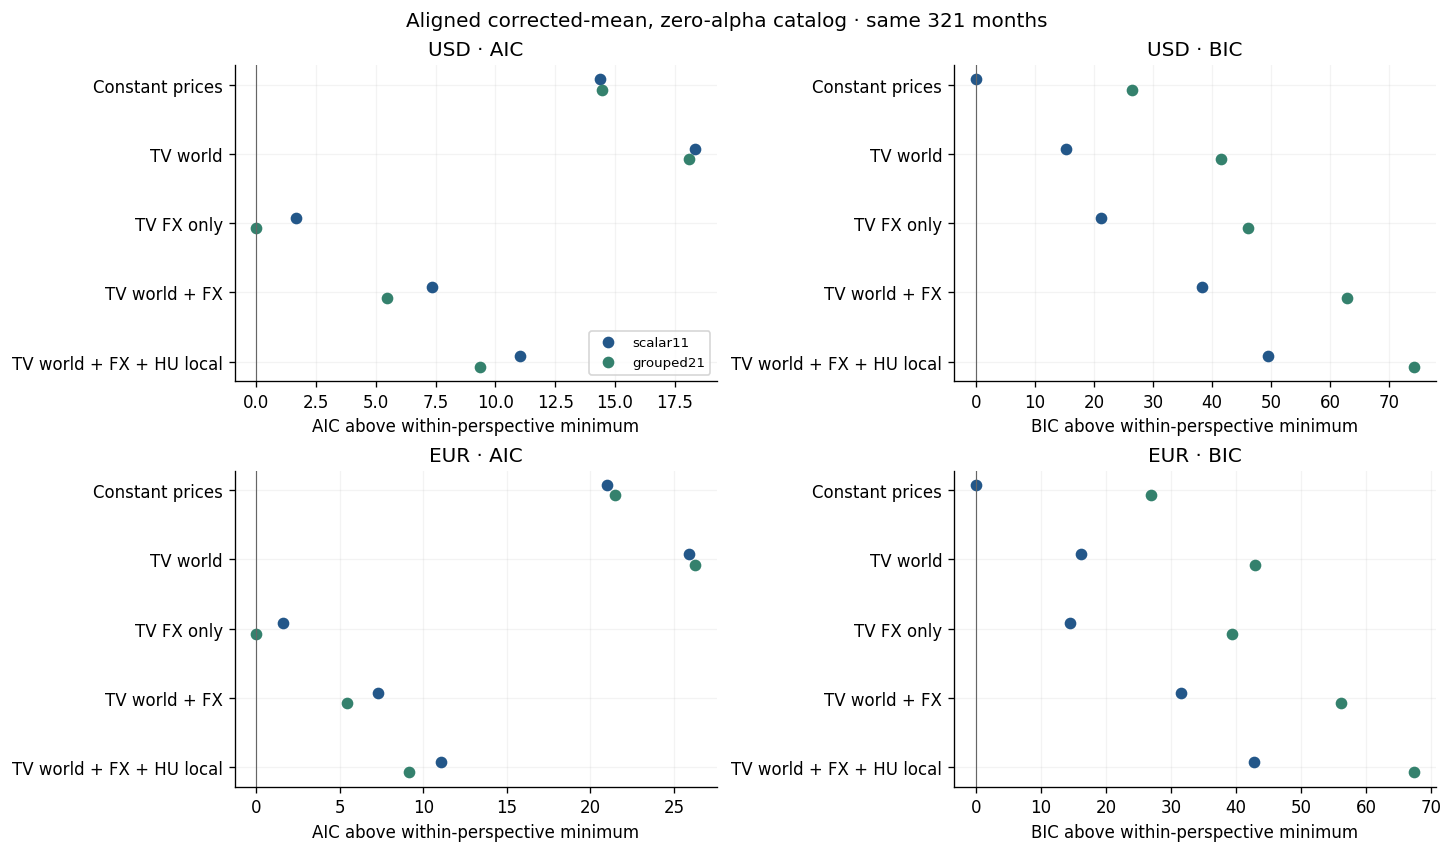

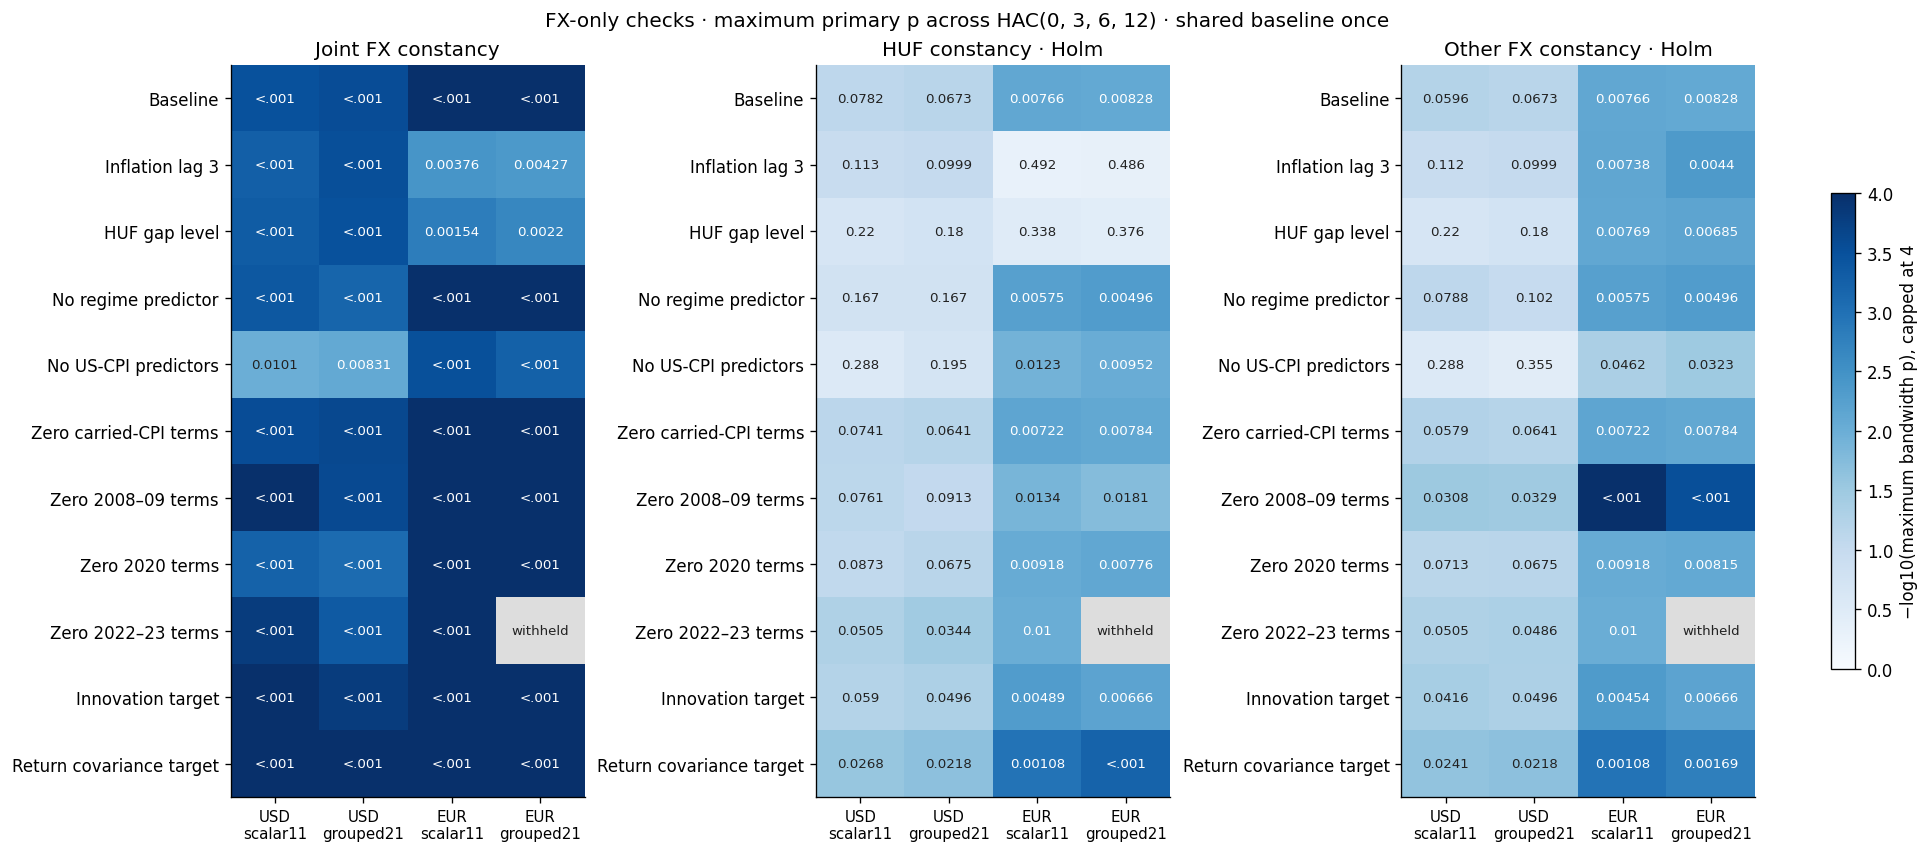

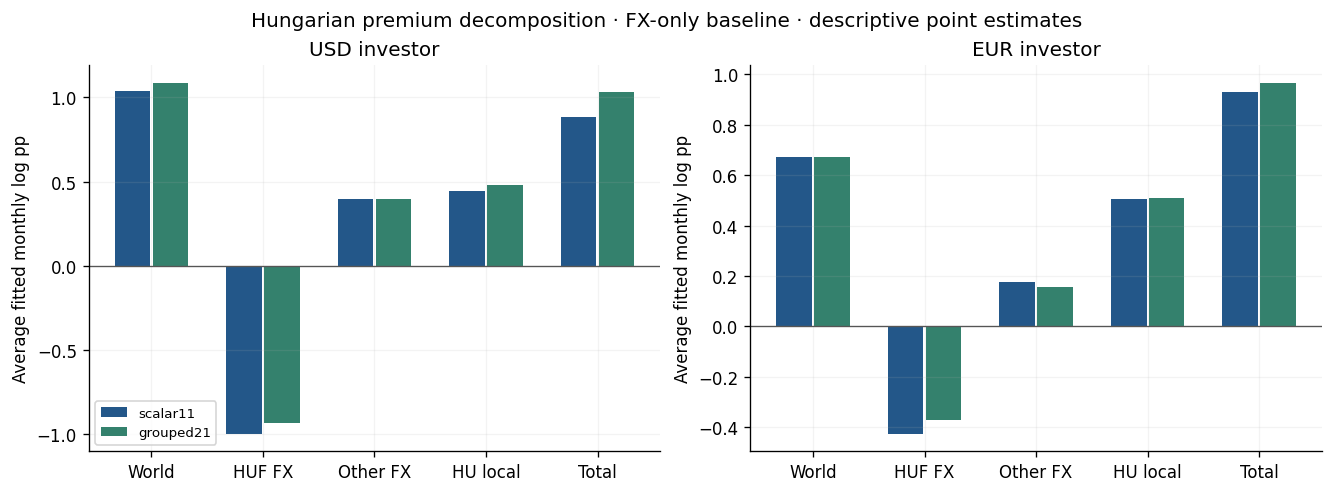

In [7]:
colors={"scalar11":"#235789","grouped21":"#34816d"}
models=["Constant prices","TV world","TV FX only","TV world + FX","TV world + FX + HU local"]
fig,axes=plt.subplots(2,2,figsize=(12,7),layout="constrained",squeeze=False)
for row,currency in enumerate(["USD","EUR"]):
    for col,criterion in enumerate(["AIC","BIC"]):
        ax=axes[row,col]
        for m,cov in enumerate(RETAINED):
            q=catalog[catalog["perspective"].eq(currency)&catalog["covariance"].eq(cov)].set_index("model").reindex(models)
            ax.plot(q[f"{criterion}_from_best"],np.arange(len(models))+.15*(m-.5),marker="o",ls="none",color=colors[cov],label=cov)
        ax.axvline(0,color="#666",lw=.7);ax.set(title=f"{currency} · {criterion}",xlabel=f"{criterion} above within-perspective minimum",yticks=range(len(models)),yticklabels=models);ax.invert_yaxis()
axes[0,0].legend(fontsize=8)
fig.suptitle("Aligned corrected-mean, zero-alpha catalog · same 321 months")
plt.savefig(OUT/"01_model_criteria.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
checks=["baseline","lag3","gap_level","no_regime","no_US_CPI","CPI_terms0","block_2008_09","block_2020","block_2022_23","target_innovations","target_returns"]
check_labels=["Baseline","Inflation lag 3","HUF gap level","No regime predictor","No US-CPI predictors","Zero carried-CPI terms","Zero 2008–09 terms","Zero 2020 terms","Zero 2022–23 terms","Innovation target","Return covariance target"]
columns=[(currency,cov) for currency in ["USD","EUR"] for cov in RETAINED]
fig,axes=plt.subplots(1,3,figsize=(16,7),layout="constrained",squeeze=False)
cmap=plt.get_cmap("Blues").copy();cmap.set_bad("#dddddd")
for ax,prefix,title in zip(axes[0],["joint","HUF","other"],["Joint FX constancy","HUF constancy · Holm","Other FX constancy · Holm"]):
    matrix=np.array([[fx_robustness.loc[(*c,v),f"{prefix}_p_max"] if fx_robustness.loc[(*c,v),f"{prefix}_complete"] and fx_robustness.loc[(*c,v),"regular"] else np.nan for c in columns] for v in checks])
    intensity=np.minimum(4,-np.log10(np.clip(matrix,1e-300,1)))
    im=ax.imshow(intensity,vmin=0,vmax=4,cmap=cmap,aspect="auto")
    for j in range(len(checks)):
        for k in range(len(columns)):
            p=matrix[j,k];label="withheld" if not np.isfinite(p) else "<.001" if p<.001 else f"{p:.3g}"
            ax.text(k,j,label,ha="center",va="center",fontsize=8,color="white" if np.isfinite(p) and intensity[j,k]>2 else "#222")
    ax.set(title=title,xticks=range(4),xticklabels=[f"{c}\n{m}" for c,m in columns],yticks=range(len(checks)),yticklabels=check_labels)
    ax.grid(False);ax.tick_params(axis="x",labelsize=9)
fig.colorbar(im,ax=list(axes[0]),label="−log10(maximum bandwidth p), capped at 4",shrink=.65)
fig.suptitle("FX-only checks · maximum primary p across HAC(0, 3, 6, 12) · shared baseline once")
plt.savefig(OUT/"02_FX_robustness_matrix.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
components=["world","HUF_FX","other_FX","local","total"]
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained",squeeze=False)
for ax,currency in zip(axes[0],["USD","EUR"]):
    for m,cov in enumerate(RETAINED):
        q=premium_summary.loc[(currency,cov)].reindex(components)
        ax.bar(np.arange(5)+.34*(m-.5),q["mean_monthly_log_pp"],width=.32,color=colors[cov],label=cov)
    ax.axhline(0,color="#555",lw=.8);ax.set(title=f"{currency} investor",ylabel="Average fitted monthly log pp",xticks=range(5),xticklabels=["World","HUF FX","Other FX","HU local","Total"])
axes[0,0].legend(fontsize=8)
fig.suptitle("Hungarian premium decomposition · FX-only baseline · descriptive point estimates")
plt.savefig(OUT/"03_Hungary_premium_decomposition.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

## 7. Final research conclusions, by investor perspective

The strongest retained finding is **joint instrument-dependent FX pricing within the corrected
currency-mean system**. It survives the retained covariance choices, the targeted FX-only checks and
estimated covariance targets. That claim is narrower than invariance to every mean specification,
evidence for each individual currency price, or proof that the full asset-pricing model is correct.

For the FX-only baseline, individual Hungarian local-price zero tests do not reject at 5% across
the fixed bandwidths. This does not establish that all local risk prices are zero: the **joint US/HU
local-price** test rejects at every bandwidth in EUR. The constant world price is positive with
HAC(0) intervals excluding zero, while its scalar-model zero test is bandwidth-sensitive. Constant
pricing, zero pricing and time variation are different hypotheses.

Within the tested ladder, added world variation and Hungarian local variation are not supported.
The earlier joint zero-alpha tests do not reject in their tested world-plus-FX branches, with wide
individual intervals. Keep both covariance models and both information criteria visible. Results are
exploratory in-sample evidence after specification search; no correction across the research search,
holdout performance claim, causal interpretation or exact Finnish replication is supplied.

In [8]:
conclusion_rows=[]
for currency in ["USD","EUR"]:
    counts=robust_counts.loc[currency]
    eligible=int(counts["complete_joint"].sum());total=int(counts["cases"].sum());stable=int(counts["reject_every_bandwidth"].sum())
    aic=winners.query("perspective == @currency and criterion == 'AIC'").iloc[0];bic=winners.query("perspective == @currency and criterion == 'BIC'").iloc[0]
    b=fx_robustness.loc[(currency,slice(None),"baseline"),:]
    p0=" / ".join(f"{b.loc[(currency,cov,'baseline'),'joint_p_HAC0']:.3g}" for cov in RETAINED)
    huf="USD HUF-block evidence is bandwidth/specification-sensitive; neither baseline block rejects at HAC(0) after Holm." if currency=="USD" else "EUR baseline HUF evidence weakens under inflation lag 3 and gap-level checks; the other-currency block can remain significant."
    conclusion_rows.append({"perspective":currency,"baseline_FX_constancy_p0_scalar_grouped":p0,"AIC_choice":aic["case"],"BIC_choice":bic["case"],"FX_only_cases":total,"complete_regular_cases":eligible,"reject_joint_at_all_bandwidths":stable,"currency_specific_qualification":huf,"mean_scope":"Pricing-restricted FX means; VAR(6) replacement did not establish the same constancy finding."})
    display(Markdown(f"**{currency} investors.** Baseline joint FX constancy p-values are **{p0}** (scalar / grouped, HAC(0)). Across the fixed FX-only set, **{stable}/{eligible}** complete regular cases reject at every bandwidth; **{total-eligible}/{total}** cases have withheld/incomplete inference. AIC selects **{aic['case']}**, while BIC selects **{bic['case']}**. {huf}"))
conclusions=pd.DataFrame(conclusion_rows).set_index("perspective")
limits=pd.DataFrame([
    ("Data and replication","Public Hungarian proxy application; different sample, world/cash proxies, two-FX basis and omitted dividend-yield conditioner."),
    ("Inference","QML/HAC and stacked target inference require regularity; model search is exploratory; non-rejection is not validation."),
    ("Mean/covariance specification","FX mean restrictions affect findings; residual variance flags remain; retain numerical failures and both covariance models."),
    ("Timing and missing conditioning data","Revised historical inputs, full-sample normalization, persistent gap-level conditioner and flagged annual US-inflation carry."),
    ("Weighting and windows","Zero-weight dates retain every GARCH update; the legacy post-float fit genuinely uses 223 observations and has its own comparison scope."),
    ("Unestimated branches","Free-alpha and local-variation diagnostics concern TV world + FX; no direct FX-only free-alpha or FX-only + TV local fit is claimed."),
    ("Forecasting and policy","No out-of-sample or causal result; fitted prices/premia are conditional model quantities."),
    ("Reproducibility and release","The lock verifies local source artifacts. data/ and output/ remain excluded from Git; a public frozen artifact bundle/release is a separate step.")],columns=["topic","qualification"])
tables={"conclusions.csv":conclusions,"model_catalog.csv":catalog,"criterion_winners.csv":winners,"main_hypotheses.csv":main_hypotheses,"FX_robustness.csv":fx_robustness,"FX_robustness_counts.csv":robust_counts,
    "coverage.csv":coverage,"case_register.csv":case_register,"all_restriction_tests.csv":all_tests,"hypothesis_register.csv":hypothesis_register,"source_table_index.csv":source_table_index,
    "mean_specification_audit.csv":mean_audit,"local_alpha_world_checks.csv":local_alpha,"Hungary_alpha_intervals_HAC0.csv":alpha_intervals,"retired_diagonal_audit.csv":retired,"ineligible_fit_rows.csv":withheld,
    "baseline_residual_flags.csv":base_diagnostics,"premium_summary.csv":premium_summary,"mean_reconciliation.csv":mean_reconciliation,"constant_prices.csv":constant_prices,"source_map.csv":source_map,"limitations.csv":limits,"verification.csv":verification}
for name,table in tables.items():table.to_csv(OUT/name)
record={"snapshot":lock["snapshot"],"source_dataset_sha256":lock["dataset_sha256"],"first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),"download_cutoff":sealed["requested_end_date"],
    "equity_alphas":"fixed zero in main catalog and FX-only synthesis; historical free-alpha diagnostics labelled","FX_means":"corrected pricing equations in main catalog and FX-only synthesis; historical alternatives labelled",
    "covariance_models":RETAINED,"HAC_lags":HAC_LAGS,"analysis":"read-only synthesis; no optimization or downloads","input_lock":LOCK_FILE,"input_lock_sha256":hashlib.sha256(lock_bytes).hexdigest(),
    "input_file_sha256":lock["files"],"archive_fit_rows":len(case_register),"archive_restriction_rows":len(all_tests),"unique_FX_only_cases":len(fx_robustness),"catalog_models":len(catalog),"python":platform.python_version(),"packages":versions}
(OUT/"synthesis_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
display(Markdown("**Final cross-perspective decision table**"));display(conclusions)
display(Markdown("**Robustness coverage, with the shared baseline counted once**"));display(robust_counts)
display(Markdown("**Scope and remaining limitations**"));display(limits)
display(Markdown(f"Saved tables, three figures and a provenance manifest under `{OUT.relative_to(ROOT)}`. The requested synthesis is complete for this recorded run; public release packaging and any additional research branches remain separate tasks."))

**USD investors.** Baseline joint FX constancy p-values are **0.000317 / 0.00028** (scalar / grouped, HAC(0)). Across the fixed FX-only set, **22/22** complete regular cases reject at every bandwidth; **0/22** cases have withheld/incomplete inference. AIC selects **USD_grouped21_FX**, while BIC selects **USD_scalar11_S1**. USD HUF-block evidence is bandwidth/specification-sensitive; neither baseline block rejects at HAC(0) after Holm.

**EUR investors.** Baseline joint FX constancy p-values are **7.69e-06 / 2.74e-05** (scalar / grouped, HAC(0)). Across the fixed FX-only set, **21/21** complete regular cases reject at every bandwidth; **1/22** cases have withheld/incomplete inference. AIC selects **EUR_grouped21_FX**, while BIC selects **EUR_scalar11_S1**. EUR baseline HUF evidence weakens under inflation lag 3 and gap-level checks; the other-currency block can remain significant.

**Final cross-perspective decision table**

,baseline_FX_constancy_p0_scalar_grouped,AIC_choice,BIC_choice,FX_only_cases,complete_regular_cases,reject_joint_at_all_bandwidths,currency_specific_qualification,mean_scope
perspective,,,,,,,,
USD,0.000317 / 0.00028,USD_grouped21_FX,USD_scalar11_S1,22,22,22,USD HUF-block evidence is bandwidth/specificat...,Pricing-restricted FX means; VAR(6) replacemen...
EUR,7.69e-06 / 2.74e-05,EUR_grouped21_FX,EUR_scalar11_S1,22,21,21,EUR baseline HUF evidence weakens under inflat...,Pricing-restricted FX means; VAR(6) replacemen...


**Robustness coverage, with the shared baseline counted once**

cases  regular  complete_joint  largest_joint_p  \
perspective covariance                                                    
EUR         grouped21      11       10              10       0.00426564   
            scalar11       11       11              11        0.0037587   
USD         grouped21      11       11              11       0.00830937   
            scalar11       11       11              11         0.010149   

                        reject_every_bandwidth  
perspective covariance                          
EUR         grouped21                       10  
            scalar11                        11  
USD         grouped21                       11  
            scalar11                        11

**Scope and remaining limitations**

,topic,qualification
0,Data and replication,Public Hungarian proxy application; different ...
1,Inference,QML/HAC and stacked target inference require r...
2,Mean/covariance specification,FX mean restrictions affect findings; residual...
3,Timing and missing conditioning data,"Revised historical inputs, full-sample normali..."
4,Weighting and windows,Zero-weight dates retain every GARCH update; t...
5,Unestimated branches,Free-alpha and local-variation diagnostics con...
6,Forecasting and policy,No out-of-sample or causal result; fitted pric...
7,Reproducibility and release,The lock verifies local source artifacts. data...


Saved tables, three figures and a provenance manifest under `output/16_research_synthesis/fixed_2026-11-13/2000-01_2026-09/recorded_run`. The requested synthesis is complete for this recorded run; public release packaging and any additional research branches remain separate tasks.